# Mission 03 — Multi-Head Attention, RoPE & Grouped-Query KV-Cache

**Squadron Hinton** · Conversational AI WiSe 2026/27 · Sector SEC-03-M45 (Pleiades) · AURA Subsystem 03

This notebook joins the four station deliverables into one pipeline. It imports the scripts instead of copying them, so the notebook and the scripts cannot drift apart. Everything runs on CPU in about a minute.

| Section | Station | Source |
|---|---|---|
| 1. Multi-head self-attention, causal mask, variance test | Systems Architect | `01_MultiHead_Attention_Core.py` |
| 2. RoPE engine, relative invariance, RoPE vs ALiBi decay | Protocol Officer | `02_RoPE_Positional_Engine.py` |
| 3. GQA, KV-cache, VRAM / bandwidth / latency benchmark | Data Specialist | `03_GQA_and_KVCache_Benchmark.py` |
| 4. Integration: a small AURA decoder generating with the cache | full squad | this notebook |
| 5. FlashAttention tiling and KV-cache DoS | Security Sentinel | `anomaly_03_sram_tiling.py`, `04_kv_cache_dos_simulation.py` |
| 6. Parameter explorer | full squad | this notebook |

In [1]:
import importlib.util, math, os, time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

def load(filename, name):
    spec = importlib.util.spec_from_file_location(name, os.path.join(os.getcwd(), filename))
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

core = load("01_MultiHead_Attention_Core.py", "core")
rope = load("02_RoPE_Positional_Engine.py", "rope")
gqa = load("03_GQA_and_KVCache_Benchmark.py", "gqa")
tiling = load("anomaly_03_sram_tiling.py", "tiling")
dos = load("04_kv_cache_dos_simulation.py", "dos")
print("torch", torch.__version__, "| threads", torch.get_num_threads())

torch 2.14.1+cpu | threads 2


## 1. Systems Architect — scaled dot-product and multi-head self-attention

$\text{Attention}(Q,K,V) = \text{softmax}(QK^\top/\sqrt{d_k} + \text{mask})\,V$, built from `nn.Linear`, `matmul` and `softmax` only.

**Variance preservation.** For $q, k$ with i.i.d. zero-mean unit-variance entries, $q \cdot k = \sum_{i=1}^{d_k} q_i k_i$ is a sum of $d_k$ independent terms of variance $E[q_i^2]E[k_i^2] = 1$, so $\text{Var}(q \cdot k) = d_k$. Dividing by $\sqrt{d_k}$ restores unit variance; without it softmax saturates (section 2 of the output).

In [2]:
core.run_all()

=== 1. Variance preservation under 1/sqrt(d_k) ===
  d_k | Var unscaled | expected | Var scaled | mean scaled | result
----------------------------------------------------------------------
   16 |       16.311 |       16 |     1.0195 |     -0.0003 | PASS
   32 |       32.053 |       32 |     1.0017 |      0.0006 | PASS
   64 |       63.760 |       64 |     0.9963 |     -0.0003 | PASS
  128 |      127.709 |      128 |     0.9977 |      0.0007 | PASS
  256 |      256.107 |      256 |     1.0004 |      0.0000 | PASS
[PASS] Scaled scores keep unit variance for every head size.

=== 2. Why scale: softmax saturation ===
 unscaled: mean max weight 0.798 | entropy 0.56 nats (uniform = 4.85) | rows with max weight > 0.99: 27% (their Jacobian norm 0.0047)
   scaled: mean max weight 0.063 | entropy 4.39 nats (uniform = 4.85) | rows with max weight > 0.99: 0%
[PASS] Unscaled logits push softmax towards one-hot; saturated rows pass almost no gradient.

=== 3. Shapes and head split ===
input (2, 16

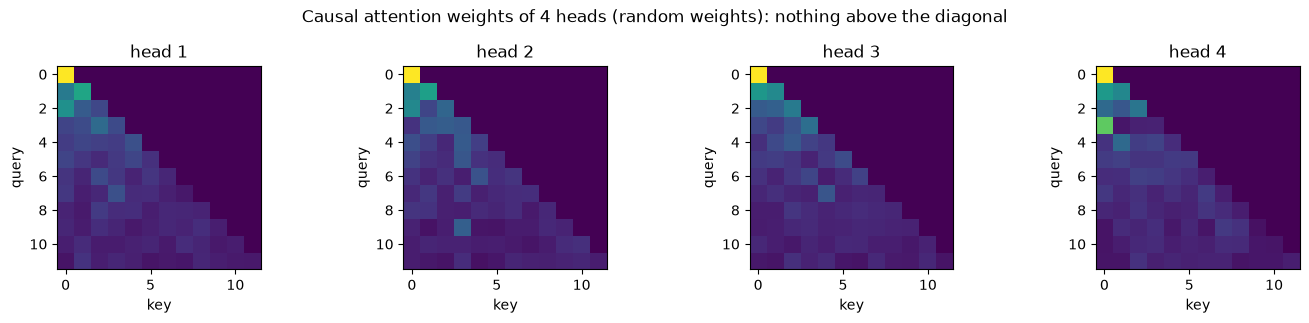

In [3]:
torch.manual_seed(0)
mha = core.MultiHeadSelfAttention(d_model=64, num_heads=4, dropout=0.0).eval()
x = torch.randn(1, 12, 64)
_, w = mha(x, causal=True)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for h, ax in enumerate(axes):
    ax.imshow(w[0, h].detach(), cmap="viridis")
    ax.set_title(f"head {h + 1}"); ax.set_xlabel("key"); ax.set_ylabel("query")
fig.suptitle("Causal attention weights of 4 heads (random weights): nothing above the diagonal")
plt.tight_layout(); plt.show()

## 2. Protocol Officer — Rotary Position Embeddings

Each pair $(x_{2i}, x_{2i+1})$ is a complex number rotated by $m\theta_i$, $\theta_i = 10000^{-2(i-1)/d}$. Since $\langle a, b\rangle = \text{Re}(a\bar b)$ per pair,

$$\langle \text{RoPE}(q,m), \text{RoPE}(k,n)\rangle = \sum_i \text{Re}\left(q_i \bar k_i\, e^{j(m-n)\theta_i}\right) = g(q,k,m-n)$$

so the absolute positions cancel and any shift $\delta$ of both tokens leaves the score unchanged.

In [4]:
rope.run_all()

=== 1. Complex multiply == explicit rotation matrix R_m ===
m =   0: max |apply_rope - R_m x| = 1.09e-07
m =   1: max |apply_rope - R_m x| = 1.77e-07
m =   7: max |apply_rope - R_m x| = 1.26e-07
m = 300: max |apply_rope - R_m x| = 3.87e-06
[PASS] apply_rope is the block-diagonal rotation R^d_{Theta,m}.

=== 2. Norm preservation ===
max | |x| - |RoPE(x)| | over 2048 vectors = 9.54e-07
[PASS] RoPE only rotates; vector lengths are unchanged.

=== 3. Relative invariance <RoPE(q,m), RoPE(k,n)> = g(q, k, m-n) ===
<RoPE(q,10), RoPE(k,25)> = 10.773232   <RoPE(q,50), RoPE(k,65)> = 10.773234   diff 1.91e-06


1000 random (q, k, m, n, delta) up to position 4096: max |shifted - original| = 7.61e-04, max |score - g(q,k,m-n)| = 4.34e-04
[PASS] Attention scores depend only on relative distance, for any translation delta.

=== 4. Position 0 is the identity ===
[PASS] RoPE(x, 0) = x.

=== 5. Long-range decay: RoPE vs ALiBi ===


distance | RoPE bound | RoPE E[score] | ALiBi h1 | ALiBi h8
       0 |      1.000 |         1.000 |     -0.0 |    -0.00
       1 |      0.970 |         0.970 |     -0.5 |    -0.00
       4 |      0.696 |         0.758 |     -2.0 |    -0.02
      16 |      0.485 |         0.618 |     -8.0 |    -0.06
      64 |      0.310 |         0.476 |    -32.0 |    -0.25
     256 |      0.201 |         0.323 |   -128.0 |    -1.00
    1024 |      0.124 |         0.203 |   -512.0 |    -4.00
RoPE decays smoothly and non-monotonically (it oscillates, never forces a score to 0);
ALiBi subtracts a fixed amount per token, so distant tokens are always penalised.
[SAVED] 02_rope_vs_alibi_decay.png

=== 6. Context extrapolation: trained at 4096, run at 32768 (d_head = 128) ===
variant                  | OOD pairs | lowest-freq angle | highest-freq step
------------------------------------------------------------------------------
plain RoPE               |   18 / 64  |        3.78 rad   |      1.0000 rad
posi

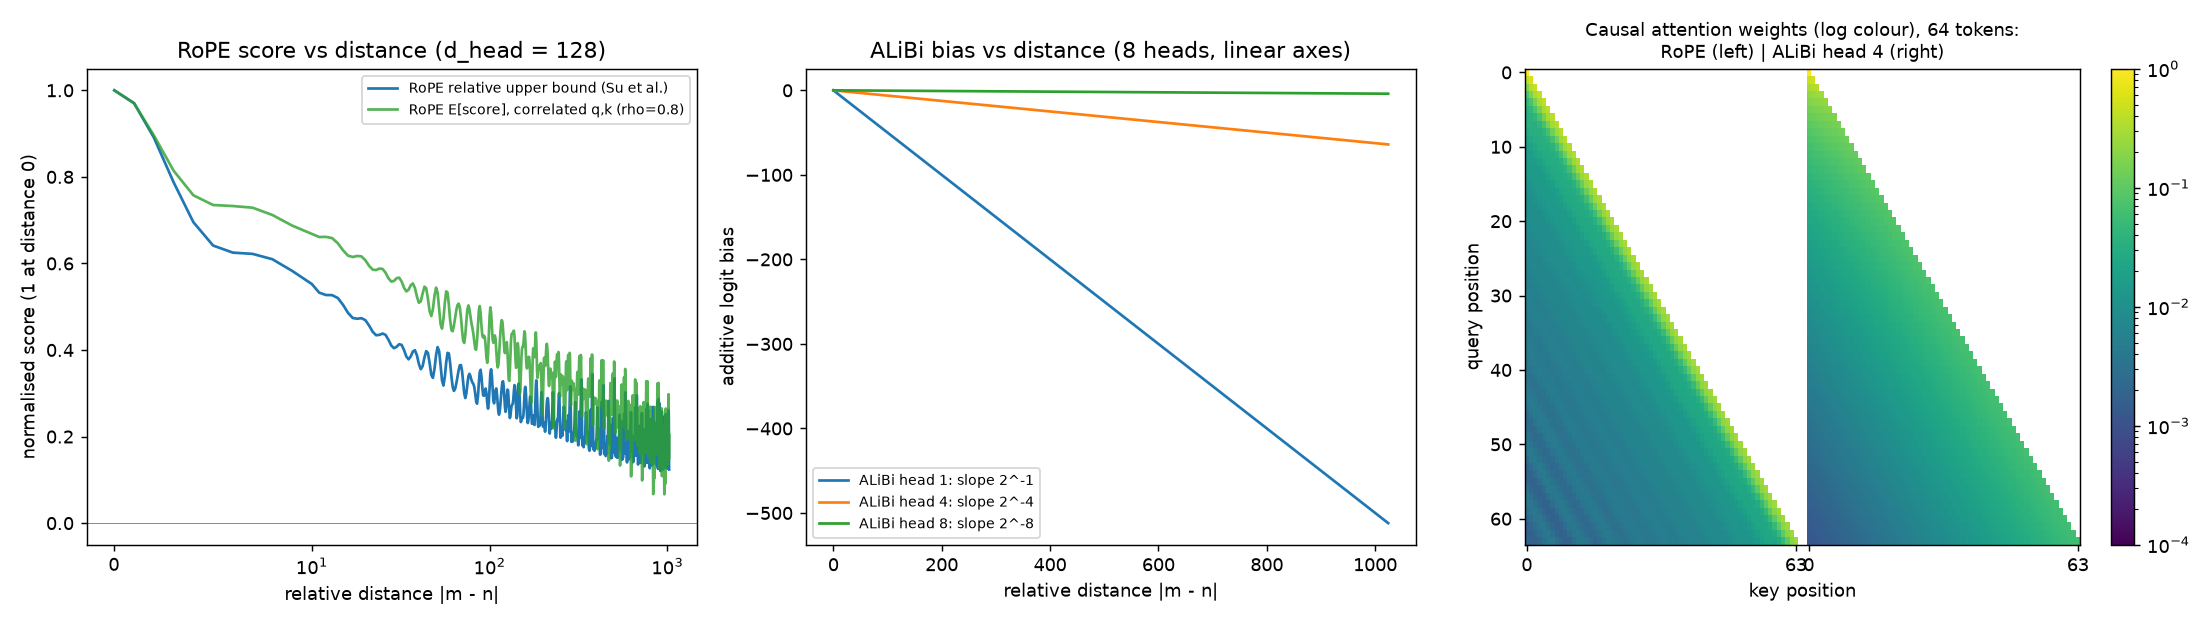

In [5]:
display(Image(rope.PLOT_PATH))

**Reading the plot.** RoPE (left) gives a soft, oscillating decay: a relevant key keeps about 20% of its score 1,000 tokens away, and nothing is ever forced to zero. ALiBi (middle) subtracts a fixed amount per token, so steep heads see only a few neighbours and shallow heads see far. In the heatmaps (log colour), RoPE spreads attention over the whole past; ALiBi head 4 concentrates it near the diagonal.

## 3. Data & Payload Specialist — GQA and KV-cache

Checks first, then a quick benchmark (N = 1024, 4096). The full table up to N = 32,768 is in `03_benchmark_results.md` (run `python 03_GQA_and_KVCache_Benchmark.py --markdown 03_benchmark_results.md`).

In [6]:
gqa.run_checks()
quick = gqa.run_kv_cache_benchmark(seq_lengths=(1024, 4096), repeats=3)

=== 1. GQA(H_KV = H_Q) == Part 1 MHA ===
max |GQA - MHA| = 0.00e+00
[PASS]

=== 2. Head grouping: reshape broadcast == repeat_interleave, head h reads KV head h // g ===
max |grouped - repeat_interleave| = 0.00e+00; query head -> KV head: [0, 0, 0, 0, 1, 1, 1, 1]
[PASS]

=== 3. Cached autoregressive decoding == full causal forward ===
MHA      prefill 8 + 24 single-token steps: max |cached - full| = 1.79e-07, cache 32.0 of 64.0 KB used
GQA 4:1  prefill 8 + 24 single-token steps: max |cached - full| = 1.49e-07, cache 8.0 of 16.0 KB used
MQA 8:1  prefill 8 + 24 single-token steps: max |cached - full| = 1.49e-07, cache 4.0 of 8.0 KB used
[PASS] The cache changes cost, not results.

=== 4. Cache overflow guard ===
5th token rejected: cache holds 4 tokens, write would end at 5
[PASS]

=== 5. KV-cache benchmark: LLaMA-3-8B shape (32 layers, 32 Q heads, head_dim 128), fp16 cache, batch 1 ===
Bandwidth = full KV-cache read once per generated token x 50 tokens/s.
Latency   = measured median of 

  1024 | MHA 32:32       |    16.0 MB |      0.50 GiB |            26.8 |          20.68 |          4.95


  1024 | GQA 32:8 (4:1)  |     4.0 MB |      0.12 GiB |             6.7 |          12.31 |          4.83


  1024 | MQA 32:1        |     0.5 MB |      0.02 GiB |             0.8 |          10.23 |          4.80
-------------------------------------------------------------------------------------------------------


  4096 | MHA 32:32       |    64.0 MB |      2.00 GiB |           107.4 |          26.95 |          5.44


  4096 | GQA 32:8 (4:1)  |    16.0 MB |      0.50 GiB |            26.8 |          17.42 |          4.95


  4096 | MQA 32:1        |     2.0 MB |      0.06 GiB |             3.4 |          12.24 |          4.81
-------------------------------------------------------------------------------------------------------
GQA 4:1 saves 75% of the cache and its traffic; MQA saves 96.9%.
At N = 4096 the MHA cache alone (2 GiB) is bigger than the model weights.



In [7]:
with open("03_benchmark_results.md") as f:
    display(Markdown(f.read()))

# Mission 03 — KV-cache benchmark results

Generated by `03_GQA_and_KVCache_Benchmark.py` on x86_64, torch 2.14.1+cpu, 2 threads.

Model shape: LLaMA 3 8B (32 layers, d_model 4096, 32 query heads, head_dim 128), fp16 cache, batch 1.
Bandwidth assumes the whole cache is read once per generated token at 50 tokens/s.
CPU latency is one layer, fp32, measured; H100 floor is (16 GB weights + KV) / 3.35 TB/s for all 32 layers.

| N | Variant | KV / layer (MB) | KV, 32 layers (GiB) | Traffic @ 50 tok/s (GB/s) | CPU ms / layer | H100 floor ms / token |
|---:|---|---:|---:|---:|---:|---:|
| 1024 | MHA 32:32 | 16.0 | 0.50 | 26.8 | 19.81 | 4.95 |
| 1024 | GQA 32:8 (4:1) | 4.0 | 0.12 | 6.7 | 12.80 | 4.83 |
| 1024 | MQA 32:1 | 0.5 | 0.02 | 0.8 | 9.98 | 4.80 |
| 4096 | MHA 32:32 | 64.0 | 2.00 | 107.4 | 29.63 | 5.44 |
| 4096 | GQA 32:8 (4:1) | 16.0 | 0.50 | 26.8 | 15.80 | 4.95 |
| 4096 | MQA 32:1 | 2.0 | 0.06 | 3.4 | 13.34 | 4.81 |
| 16384 | MHA 32:32 | 256.0 | 8.00 | 429.5 | 53.50 | 7.36 |
| 16384 | GQA 32:8 (4:1) | 64.0 | 2.00 | 107.4 | 30.53 | 5.44 |
| 16384 | MQA 32:1 | 8.0 | 0.25 | 13.4 | 17.89 | 4.87 |
| 32768 | MHA 32:32 | 512.0 | 16.00 | 859.0 | 89.64 | 9.92 |
| 32768 | GQA 32:8 (4:1) | 128.0 | 4.00 | 214.7 | 41.60 | 6.08 |
| 32768 | MQA 32:1 | 16.0 | 0.50 | 26.8 | 26.53 | 4.95 |

## Step cost with and without the cache (1 layer, d_model 1024, GQA 16:4)

| N | Cached step (ms) | Recompute (ms) | Speed-up |
|---:|---:|---:|---:|
| 256 | 1.73 | 40.46 | 23x |
| 512 | 1.64 | 98.07 | 60x |
| 1024 | 1.92 | 445.12 | 232x |
| 2048 | 2.59 | 1394.74 | 539x |


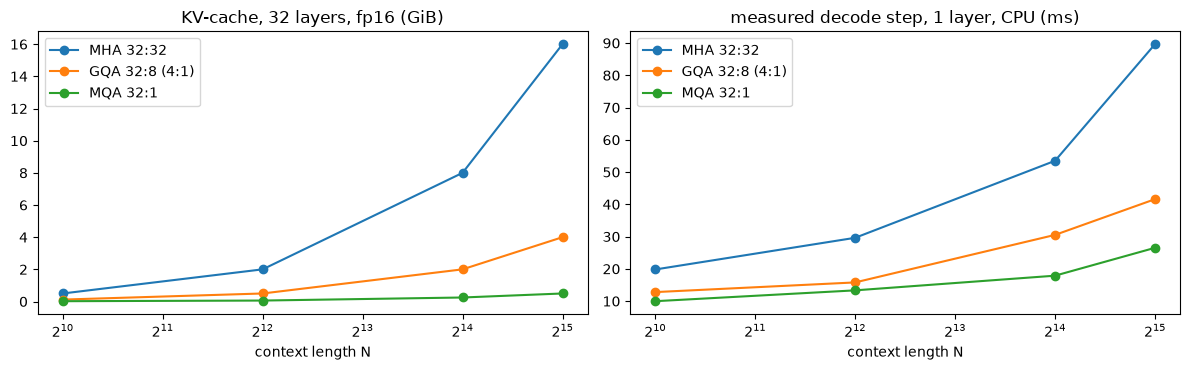

In [8]:
full = [l for l in open("03_benchmark_results.md") if l.startswith("| ") and "MB" not in l and "N |" not in l]
rows = [[c.strip() for c in l.strip().strip("|").split("|")] for l in full if len(l.split("|")) > 8]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for variant in ("MHA 32:32", "GQA 32:8 (4:1)", "MQA 32:1"):
    r = [x for x in rows if x[1] == variant]
    n = [int(x[0]) for x in r]
    axes[0].plot(n, [float(x[3]) for x in r], "o-", label=variant)
    axes[1].plot(n, [float(x[5]) for x in r], "o-", label=variant)
axes[0].set_title("KV-cache, 32 layers, fp16 (GiB)"); axes[1].set_title("measured decode step, 1 layer, CPU (ms)")
for ax in axes:
    ax.set_xscale("log", base=2); ax.set_xlabel("context length N"); ax.legend()
plt.tight_layout(); plt.show()

**Findings.** The cache grows linearly in N and in H_KV: GQA 4:1 saves exactly 75%, MQA 96.9%. At N = 32,768 an MHA cache (16 GiB) is larger than the 8B model's weights. Decoding reads the whole cache every token, so measured latency follows the cache size: at 32k, GQA is about 2× faster per layer than MHA on this CPU. At small N the weight projections dominate and the three variants are close. The cache is also what makes decoding feasible at all: re-running the full sequence for every new token was over 500× slower at N = 2048.

Note on the briefing: a cached step costs O(N), not O(1), because it still reads all N cached keys and values. Total generation is O(N²) with the cache and O(N³) without it.

## 4. Integration — a small AURA decoder generating with RoPE + GQA + KV-cache

Two pre-norm decoder layers (RMSNorm → GQA attention with RoPE → RMSNorm → SwiGLU MLP) with random weights. We generate 48 tokens greedily twice: once re-running the whole sequence every step, once with one `KVCache` per layer. The token sequences must be identical; only the cost differs.

In [9]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__(); self.weight = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

class DecoderLayer(nn.Module):
    def __init__(self, d, hq, hkv, max_len):
        super().__init__()
        self.n1, self.n2 = RMSNorm(d), RMSNorm(d)
        self.attn = gqa.GQAAttention(d, hq, hkv, use_rope=True, max_seq_len=max_len)
        self.gate, self.up, self.down = nn.Linear(d, 4 * d, bias=False), nn.Linear(d, 4 * d, bias=False), nn.Linear(4 * d, d, bias=False)
    def forward(self, x, start_pos=0, cache=None):
        x = x + self.attn(self.n1(x), start_pos=start_pos, kv_cache=cache)
        h = self.n2(x)
        return x + self.down(F.silu(self.gate(h)) * self.up(h))

class TinyAURA(nn.Module):
    def __init__(self, vocab=512, d=256, hq=8, hkv=2, layers=2, max_len=256):
        super().__init__()
        self.emb = nn.Embedding(vocab, d)
        self.layers = nn.ModuleList(DecoderLayer(d, hq, hkv, max_len) for _ in range(layers))
        self.norm, self.head = RMSNorm(d), nn.Linear(d, vocab, bias=False)
        self.cfg = dict(hkv=hkv, head_dim=d // hq, max_len=max_len)
    def forward(self, ids, start_pos=0, caches=None):
        x = self.emb(ids)
        for i, layer in enumerate(self.layers):
            x = layer(x, start_pos, None if caches is None else caches[i])
        return self.head(self.norm(x))

    @torch.inference_mode()
    def generate(self, prompt, steps, use_cache):
        ids = prompt.clone()
        if not use_cache:
            for _ in range(steps):
                ids = torch.cat([ids, self(ids)[:, -1:].argmax(-1)], dim=1)
            return ids, None
        caches = [gqa.KVCache(1, self.cfg["max_len"], self.cfg["hkv"], self.cfg["head_dim"]) for _ in self.layers]
        logits = self(ids, 0, caches)                      # prefill the whole prompt once
        for _ in range(steps):
            nxt = logits[:, -1:].argmax(-1)
            pos = ids.size(1)
            ids = torch.cat([ids, nxt], dim=1)
            logits = self(nxt, pos, caches)                  # one token per step
        return ids, caches

torch.manual_seed(3)
model = TinyAURA().eval()
prompt = torch.randint(0, 512, (1, 16))
t0 = time.perf_counter(); no_cache, _ = model.generate(prompt, 48, use_cache=False); t1 = time.perf_counter()
with_cache, caches = model.generate(prompt, 48, use_cache=True); t2 = time.perf_counter()
print("identical tokens:", torch.equal(no_cache, with_cache))
print(f"without cache {1000 * (t1 - t0):.0f} ms | with cache {1000 * (t2 - t1):.0f} ms")
print(f"cache: {sum(c.used_memory_mb() for c in caches) * 1024:.0f} KB used of "
      f"{sum(c.get_memory_mb() for c in caches) * 1024:.0f} KB reserved ({caches[0].seq_len} tokens x 2 layers)")
assert torch.equal(no_cache, with_cache)

identical tokens: True
without cache 323 ms | with cache 167 ms
cache: 64 KB used of 256 KB reserved (64 tokens x 2 layers)


## 5. Security Sentinel — FlashAttention tiling and KV-cache DoS

### 5a. Side quest: SRAM-tiled attention with counted HBM traffic

In [10]:
_ = tiling.run()

=== Anomaly 03: SRAM-tiled attention vs standard attention (simulated HBM traffic) ===
SRAM budget M = 100,000 elements (~195 KB fp16, one H100 SM has 228 KB), head_dim d = 64 -> block B_r = B_c = 128

1. Correctness and counted traffic (actual runs)
    N | causal | max |tiled - std| | std elements | tiled elements | reduction
  512 |  False |          2.09e-07 |    1,179,648 |        328,192 |      3.6x
  512 |   True |          5.07e-07 |    1,179,648 |        229,888 |      5.1x
 1024 |  False |          2.68e-07 |    4,456,448 |      1,180,672 |      3.8x
 1024 |   True |          5.96e-07 |    4,456,448 |        721,920 |      6.2x


 2048 |  False |          8.94e-08 |   17,301,504 |      4,458,496 |      3.9x
 2048 |   True |          4.17e-07 |   17,301,504 |      2,492,416 |      6.9x
(counted traffic equals the closed form for every run)

2. Scaling to long context (closed form, verified above)
     N | std (MB fp16) | tiled (MB) | tiled causal (MB) | reduction | causal reduction
  1024 |           8.9 |        2.4 |               1.4 |      3.8x |             6.2x
  4096 |         136.3 |       34.6 |              18.4 |      3.9x |             7.4x
 16384 |        2155.9 |      541.1 |             274.8 |      4.0x |             7.8x


 65536 |       34393.3 |     8606.8 |            4320.3 |      4.0x |             8.0x
Both are still quadratic in N. Tiled traffic is ~ (N / B) * 2Nd = 2N^2 d / B, so the reduction
tends to 4N^2 / (2N^2 d / B) = 2B / d = 4x (double with causal block skipping).
Since B = Theta(M / d), the tiled traffic is Theta(N^2 d^2 / M): more SRAM, bigger blocks, less traffic.

3. Effect of SRAM size (N = 16384, non-causal)
M (elements) | block | reduction
      25,000 |    64 |      2.0x
      50,000 |   128 |      4.0x
     100,000 |   128 |      4.0x
     200,000 |   256 |      7.9x

[PASS] Tiled attention needs 3.9x less HBM traffic at N = 4096 (7.4x causal): side-quest target of 3x met.


Standard attention moves $4N^2 + 4Nd$ elements; tiled attention moves $\approx 2N^2d/B$, i.e. $\Theta(N^2d^2/M)$. The output is identical; only traffic changes. The full derivation is in `04_Memory_Hierarchy_and_Safety_Audit.md` §1.

### 5b. KV-cache denial of service on one 80 GB H100

=== 1. Sessions at N = 65,536 before CUDA OOM (80 GB H100, 8B model, fp16) ===
KV budget: 80 - 16.06 (weights) - 4 (reserve) = 59.94 GB

architecture             | KiB / token | GB / session | max sessions | tokens in budget
MHA 32:32                |       512.0 |        34.36 |            1 |         114,326
GQA 32:8                 |       128.0 |         8.59 |            6 |         457,306
MQA 32:1                 |        16.0 |         1.07 |           55 |       3,658,447
MLA d_c=512 (+64 RoPE)   |        36.0 |         2.42 |           24 |       1,625,977

=== 2. 60-turn attack timeline, GQA 32:8, rogue client from turn 10 ===
Crew: 1 new session every 2 turns, 20 turns x 350 tokens each (~10 live sessions).
Rogue: from turn 10, 4 new sessions per turn, 8,192 tokens per turn, never closes.

policy       | attack | OOM panics | first OOM | crew turns served | crew sessions lost | rejected req. | peak empty reserve
static       |     no |          3 |        12 |              

[SAVED] 04_dos_memory_timeline.png


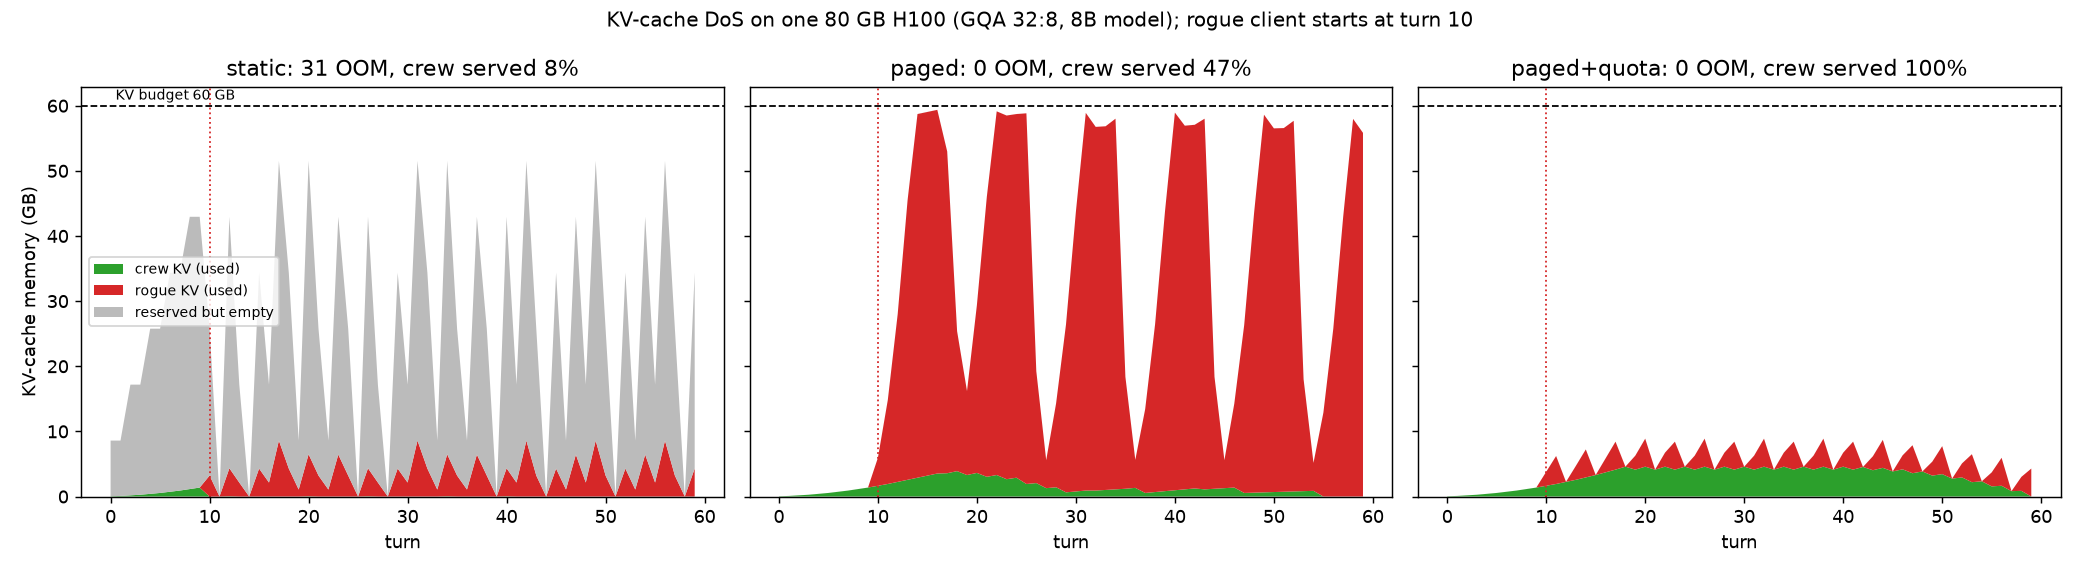

In [11]:
_ = dos.static_capacity()
dos.plot(dos.run_timeline())
display(Image(dos.PLOT_PATH))

Static preallocation crashes even without an attacker. PagedAttention removes the crashes and the waste, but a single client can still take all the memory (crew served 47%). Only per-client quotas on top of paging keep the crew at 100%. Analysis and the MLA comparison: audit §2–3.

## 6. Parameter explorer

Change the values and re-run the cell to explore attention parameters (the course portal's simulator could not be found in the site bundle; this cell plays its role).

In [12]:
def explore(d_model=4096, q_heads=32, kv_heads=8, layers=32, context=32768, sessions=1, bytes_per_value=2,
            hbm_gb=80, weights_gb=16.06, tokens_per_s=50):
    head_dim = d_model // q_heads
    per_token = 2 * bytes_per_value * layers * kv_heads * head_dim
    total = per_token * context * sessions
    budget = (hbm_gb - weights_gb - 4) * 1e9
    print(f"head_dim {head_dim}, group size {q_heads // kv_heads} query heads per KV head")
    print(f"KV per token: {per_token / 1024:.1f} KiB | per session at {context:,} tokens: {per_token * context / 1e9:.2f} GB")
    print(f"{sessions} session(s): {total / 1e9:.2f} GB of {budget / 1e9:.1f} GB KV budget -> "
          f"{'fits' if total <= budget else 'CUDA OOM'}; max sessions {int(budget // (per_token * context))}")
    print(f"decode traffic at {tokens_per_s} tok/s per session: {total * tokens_per_s / 1e9:.1f} GB/s "
          f"(H100 HBM: 3,350 GB/s)")
    print(f"attention matrix if materialised: {q_heads * context ** 2 * bytes_per_value / 1e9:.1f} GB per layer")

explore()                                   # LLaMA-3-8B, 32k context
print()
explore(kv_heads=32, context=65536)         # same model with MHA at 64k: does not fit

head_dim 128, group size 4 query heads per KV head
KV per token: 128.0 KiB | per session at 32,768 tokens: 4.29 GB
1 session(s): 4.29 GB of 59.9 GB KV budget -> fits; max sessions 13
decode traffic at 50 tok/s per session: 214.7 GB/s (H100 HBM: 3,350 GB/s)
attention matrix if materialised: 68.7 GB per layer

head_dim 128, group size 1 query heads per KV head
KV per token: 512.0 KiB | per session at 65,536 tokens: 34.36 GB
1 session(s): 34.36 GB of 59.9 GB KV budget -> fits; max sessions 1
decode traffic at 50 tok/s per session: 1718.0 GB/s (H100 HBM: 3,350 GB/s)
attention matrix if materialised: 274.9 GB per layer


## Squadron sign-off

See `README.md` in this folder: each officer ticks their own box.